In [1]:
# CELL 1: Machine detection (WSL vs DAIC) and path setup
import os
import socket

# Detect which machine we're running on
hostname = socket.gethostname()

if "daic" in hostname or "tudelft" in hostname or "hpc" in hostname:
    # Running on DAIC
    os.environ["HF_HOME"] = "/tudelft.net/staff-umbrella/lsuryana/huggingface"
    MODEL_PATH = "Qwen/Qwen2-VL-7B-Instruct"
    DATA_PATH = "/tudelft.net/staff-umbrella/lsuryana/rq2-posthoc-driving/data/nuscenes"
else:
    # Running on WSL/local
    os.environ["HF_HOME"] = os.path.expanduser("~/.cache/huggingface")
    MODEL_PATH = "Qwen/Qwen2-VL-7B-Instruct"
    DATA_PATH = os.path.expanduser("~/rq2-posthoc-driving/data/nuscenes")

print(f"Running on: {hostname}")
print(f"HF_HOME: {os.environ['HF_HOME']}")
print(f"MODEL_PATH: {MODEL_PATH}")
print(f"DATA_PATH: {DATA_PATH}")

Running on: DESKTOP-UO71C2L
HF_HOME: /home/lsuryana/.cache/huggingface
MODEL_PATH: Qwen/Qwen2-VL-7B-Instruct
DATA_PATH: /home/lsuryana/rq2-posthoc-driving/data/nuscenes


In [2]:
# CELL 2: Load model
# ─────────────────────────────────────────────────────────────────────────────
import json, os, re, torch, time, gc, math
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor
from qwen_vl_utils import process_vision_info
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# MODEL_PATH = "/home/lsuryana/.cache/huggingface/hub/Qwen2-VL-7B-Instruct"
print("Loading model...")
model = Qwen2VLForConditionalGeneration.from_pretrained(
    MODEL_PATH, torch_dtype="auto", device_map="cuda")
processor = AutoProcessor.from_pretrained(MODEL_PATH)
print(f"Model loaded. VRAM: {round(torch.cuda.memory_allocated()/1e9,2)} GB")

Loading model...


`Qwen2VLRotaryEmbedding` can now be fully parameterized by passing the model config through the `config` argument. All other arguments will be removed in v4.46


Loading checkpoint shards:   0%|          | 0/5 [00:00<?, ?it/s]

Model loaded. VRAM: 16.63 GB


In [3]:
# CELL 3: Load data, prompts, and helper functions
import json, os, re, torch, time, gc, math
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from qwen_vl_utils import process_vision_info

from scripts.labels import continuous_to_drivelm_label

with open('data/scenarios/preprocessed_scenarios.json') as f:
    data = json.load(f)

# 3-step pipeline prompts
p1 = open('prompts/step1_perception.txt').read()   # Perception
p2 = open('prompts/step2_projection.txt').read()   # Projection
p3 = open('prompts/step3_planning.txt').read()      # Planning -- Hamiltonian
p3_drivelm = open('prompts/step3_planning_drivelm.txt').read()  # Planning -- DriveLM style

IMAGE_SIZE = (640, 360)

def resize_image(path):
    base, ext = os.path.splitext(path)
    tmp = f"{base}_r{ext}"
    if not os.path.exists(tmp):
        img = Image.open(path).convert('RGB').resize(IMAGE_SIZE, Image.LANCZOS)
        img.save(tmp, quality=85)
    return tmp

def get_image_sequence(s):
    """Always the 4 fixed frames: tm3, tm2, tm1, t0. No posthoc/future frames
    in this pipeline version -- images are re-sent at every step."""
    fd = s['frame_dir']
    n_past = s.get('n_past', 0)
    past_frames = []
    if n_past >= 3:
        past_frames = [f"{fd}/tm3.jpg", f"{fd}/tm2.jpg", f"{fd}/tm1.jpg"]
    elif n_past == 2:
        past_frames = [f"{fd}/tm2.jpg", f"{fd}/tm1.jpg"]
    elif n_past == 1:
        past_frames = [f"{fd}/tm1.jpg"]
    return past_frames + [f"{fd}/t0.jpg"]

def build_image_description(n_past):
    lines = []
    labels = [("tm3", "t-3 (1.5 s before the decision point)"),
              ("tm2", "t-2 (1.0 s before the decision point)"),
              ("tm1", "t-1 (0.5 s before the decision point)")]
    labels = labels[3 - n_past:] if n_past < 3 else labels
    for i, (_, desc) in enumerate(labels, start=1):
        lines.append(f"- Image {i}: {desc}")
    lines.append(f"- Image {len(labels)+1}: t0 (decision point)")
    return "\n".join(lines)

def run_inference(messages, max_tokens=1024):
    torch.cuda.empty_cache()
    gc.collect()
    text = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True)
    has_images = any(
        isinstance(item, dict) and item.get('type') == 'image'
        for msg in messages
        for item in msg.get('content', [])
    )
    if has_images:
        image_inputs, _ = process_vision_info(messages)
        inputs = processor(
            text=[text], images=image_inputs, return_tensors="pt").to("cuda")
    else:
        inputs = processor(text=[text], return_tensors="pt").to("cuda")
    with torch.no_grad():
        out = model.generate(
            **inputs, max_new_tokens=max_tokens,
            temperature=0.0, do_sample=False)
    trimmed = out[:, inputs['input_ids'].shape[1]:]
    result  = processor.decode(trimmed[0], skip_special_tokens=True)
    del inputs, out, trimmed
    torch.cuda.empty_cache()
    return result

def parse_step(raw, step):
    patterns = {
        'perception_summary': r'PERCEPTION[ _]SUMMARY:\s*(.*?)$',
        'projection_summary': r'PROJECTION[ _]SUMMARY:\s*(.*?)$', 
        'planning_summary':   r'PLANNING[ _]SUMMARY:\s*(.*?)(?=FINAL SPEED:|$)',
        'final_speed':        r'FINAL SPEED:\s*(.+?)(?:\n|$)',
        'final_direction':    r'FINAL DIRECTION:\s*(.+?)(?:\n|$)',
    }
    match = re.search(patterns[step], raw, re.DOTALL | re.MULTILINE | re.IGNORECASE)
    return match.group(1).strip() if match else ''

def get_gt_continuous(s):
    return s.get('gt_continuous') or {}

def get_prev_continuous(s):
    return s.get('prev_continuous') or {}

def get_past_behavior_label(past_traj, n_past):
    if n_past == 0 or not past_traj:
        return continuous_to_drivelm_label(0.0, 0.0)
    earliest = past_traj[0]
    dx = 0.0 - earliest['x']
    dy = 0.0 - earliest['y']
    dt = n_past * 0.5
    dist = math.sqrt(dx**2 + dy**2)
    avg_speed_mps = dist / dt
    angle_deg = math.degrees(math.atan2(dy, dx)) if dist > 0.01 else 0.0
    return continuous_to_drivelm_label(avg_speed_mps, angle_deg)

print(f"Loaded {len(data)} scenario variants.")
print("Helper functions ready (3-step pipeline: Perception -> Projection -> Planning).")

Loaded 65 scenario variants.
Helper functions ready.


In [4]:
# CELL 4: build_context_header + run_condition (3-step: Perception -> Projection -> Planning)

def build_context_header(s):
    n_past    = s.get('n_past', 0)
    past_traj = s.get('past_trajectory', [])
    prev_cont = get_prev_continuous(s)
    ego_goal  = s.get('ego_goal', 'continue driving safely along the current road')
    scenario_text = s.get('scenario_text', '')
    img_desc  = build_image_description(n_past)

    past_traj_text = ""
    if n_past >= 3:
        past_traj_text = (
            f"  t-1.5s: x={past_traj[0]['x']}, y={past_traj[0]['y']}\n"
            f"  t-1.0s: x={past_traj[1]['x']}, y={past_traj[1]['y']}\n"
            f"  t-0.5s: x={past_traj[2]['x']}, y={past_traj[2]['y']}\n"
        )
    elif n_past == 2:
        past_traj_text = (
            f"  t-1.0s: x={past_traj[0]['x']}, y={past_traj[0]['y']}\n"
            f"  t-0.5s: x={past_traj[1]['x']}, y={past_traj[1]['y']}\n"
        )

    if n_past >= 1:
        dir_lbl, spd_lbl = get_past_behavior_label(past_traj, n_past)
        past_traj_text += (
            f"Historical ego behaviour:\n"
            f"  Speed:     {spd_lbl}\n"
            f"  Direction: {dir_lbl}\n"
        )

    if prev_cont:
        past_traj_text += (
            f"Historical ego motion state (numeric):\n"
            f"  avg speed:    {prev_cont.get('avg_speed_mps', 0)} m/s "
            f"({prev_cont.get('avg_speed_kph', 0)} km/h)\n"
            f"  acceleration: {prev_cont.get('acceleration_mps2', 0)} m/s2\n"
            f"  heading:      {prev_cont.get('angle_overall_deg', 0)} degrees\n"
            f"  yaw rate:     {prev_cont.get('yaw_rate_deg_s', 0)} deg/s\n"
        )

    header = (
        f"You are given four sequential images of the same driving scene.\n"
        f"Image timeline:\n{img_desc}\n\n"
        f"Ego vehicle goal:\n{ego_goal}\n\n"
        f"Historical ego trajectory (relative to t0):\n"
        f"{past_traj_text}"
    )

    return header


def run_condition_v3(s):
    """
    3-step pipeline. Images sent at EVERY step (per current prompt design --
    higher image-token cost than the old 5-step version, which only sent
    images at Step 1). Confirm this is intended if compute time is a concern.
    """
    images  = get_image_sequence(s)
    resized = [resize_image(img) for img in images]
    context_header = build_context_header(s)

    def img_content():
        return [{"type": "image", "image": p} for p in resized]

    # Step 1: Perception (images)
    prompt1 = context_header + "\n" + p1
    msg1 = [{"role": "user", "content": img_content() + [{"type": "text", "text": prompt1}]}]
    raw1 = run_inference(msg1, max_tokens=1024)
    perc_summary = parse_step(raw1, 'perception_summary') or raw1.strip()

    # Step 2: Projection (images + Step 1 output)
    prompt2 = (
        context_header +
        f"\nPerception results (Step 1):\n{raw1}\n\n"
    ) + p2
    msg2 = [{"role": "user", "content": img_content() + [{"type": "text", "text": prompt2}]}]
    raw2 = run_inference(msg2, max_tokens=1024)
    proj_summary = parse_step(raw2, 'projection_summary') or raw2.strip()

    # Step 3: Planning -- Hamiltonian (images + Step 1 + Step 2 output)
    prompt3 = (
        context_header +
        f"\nPerception results (Step 1):\n{raw1}\n\n"
        f"Projection results (Step 2):\n{raw2}\n\n"
    ) + p3
    msg3 = [{"role": "user", "content": img_content() + [{"type": "text", "text": prompt3}]}]
    raw3 = run_inference(msg3, max_tokens=2048)
    plan_summary = parse_step(raw3, 'planning_summary') or raw3.strip()
    final_speed = parse_step(raw3, 'final_speed')
    final_direction = parse_step(raw3, 'final_direction')

    gt = get_gt_continuous(s)
    gt_direction = gt.get('direction_label', '')
    gt_speed     = gt.get('speed_label', '')

    return {
        'perception_raw':     raw1,
        'perception_summary': perc_summary,
        'projection_raw':     raw2,
        'projection_summary': proj_summary,
        'planning_raw':       raw3,
        'planning_summary':   plan_summary,
        'direction':          final_direction,
        'speed':              final_speed,
        'gt_direction':       gt_direction,
        'gt_speed':           gt_speed,
        'direction_correct':  final_direction == gt_direction,
        'speed_correct':      final_speed == gt_speed,
        'full_correct':       (final_direction == gt_direction) and (final_speed == gt_speed),
        'n_images':           len(images),
    }


def run_planning_drivelm_v3(saved_result, s):
    """
    Reuses frozen Step 1 + Step 2 from a completed run_condition_v3() result,
    reruns only Step 3 with the DriveLM-style planning prompt.
    """
    context_header = build_context_header(s)
    images  = get_image_sequence(s)
    resized = [resize_image(img) for img in images]

    def img_content():
        return [{"type": "image", "image": p} for p in resized]

    raw1 = saved_result['perception_raw']
    raw2 = saved_result['projection_raw']

    prompt3b = (
        context_header +
        f"\nPerception results (Step 1):\n{raw1}\n\n"
        f"Behaviour assessment (Step 2):\n{raw2}\n\n"
    ) + p3_drivelm
    msg3b = [{"role": "user", "content": img_content() + [{"type": "text", "text": prompt3b}]}]
    raw3b = run_inference(msg3b, max_tokens=2048)
    plan_summary_b = parse_step(raw3b, 'planning_summary') or raw3b.strip()
    final_speed_b = parse_step(raw3b, 'final_speed')
    final_direction_b = parse_step(raw3b, 'final_direction')

    gt_direction = saved_result['gt_direction']
    gt_speed     = saved_result['gt_speed']

    return {
        'planning_raw_drivelm':     raw3b,
        'planning_summary_drivelm': plan_summary_b,
        'direction_drivelm':        final_direction_b,
        'speed_drivelm':            final_speed_b,
        'direction_correct_drivelm': final_direction_b == gt_direction,
        'speed_correct_drivelm':     final_speed_b == gt_speed,
        'full_correct_drivelm':      (final_direction_b == gt_direction) and (final_speed_b == gt_speed),
    }


# Verify context header + Step 1 prompt for sample 0
print("Context header for sample 0:\n")
print(build_context_header(data[0]))

Context headers for sample 0:

NON POST-HOC:
You have access to 4 images showing the driving scene:
- Image 1: t-3 (1.5 seconds before decision point)
- Image 2: t-2 (1.0 second before decision point)
- Image 3: t-1 (0.5 seconds before decision point)
- Image 4: t0  (current frame -- DECISION POINT)

Ego vehicle goal: continue straight along the current road

Ego vehicle past trajectory (x=forward meters, y=left meters, relative to t0):
  t-1.5s: x=-7.939, y=0.057
  t-1.0s: x=-5.156, y=0.029
  t-0.5s: x=-2.189, y=0.007
Ego vehicle past behavior (aggregated over past window):
  speed:     driving with normal speed
  direction: going straight
Ego vehicle past motion state:
  not available

Scenario details at the decision point (t0), as specified for this experimental variant:
  Stays in place | Stays in place | Driving normally (no brake lamp) | Green | Ground truth speed


POST-HOC:
You have access to 7 images showing the driving scene:
- Image 1: t-3 (1.5 seconds before decision point

In [5]:
# CELL 5: Step-by-step validation on one sample
# ─────────────────────────────────────────────────────────────────────────────

s = data[0]
print(f"Sample: {s['sample_token']}")
print(f"Scenario text: {s.get('scenario_text', '(none)')}\n")
print("="*70)

result = run_condition_v3(s)

print("STEP 1 -- PERCEPTION (raw model output):")
print(result['perception_raw'])
print("\n" + "-"*70)
print("Perception summary (parsed):", result['perception_summary'][:300])

print("\n" + "="*70)
print("STEP 2 -- PROJECTION (raw model output):")
print(result['projection_raw'])
print("\n" + "-"*70)
print("Projection summary (parsed):", result['projection_summary'][:300])

print("\n" + "="*70)
print("STEP 3 -- PLANNING (raw model output):")
print(result['planning_raw'])
print("\n" + "-"*70)
print("Planning summary (parsed):", result['planning_summary'][:300])

print("\n" + "="*70)
print(f"FINAL SPEED:     '{result['speed']}'")
print(f"FINAL DIRECTION: '{result['direction']}'")
if not result['speed'] or not result['direction']:
    print("\nWARNING: speed or direction came back empty -- check that the "
          "model actually produced 'FINAL SPEED:'/'FINAL DIRECTION:' lines "
          "in the Step 3 raw output above. If it didn't, the prompt's final "
          "instruction may need to be more forceful, or max_tokens for Step 3 "
          "may be too low (currently 2048) and the answer got cut off.")

print(f"\n[diagnostic vs real recorded trajectory]")
print(f"  direction: predicted='{result['direction']}' vs real='{result['gt_direction']}' "
      f"({'match' if result['direction_correct'] else 'differ'})")
print(f"  speed:     predicted='{result['speed']}' vs real='{result['gt_speed']}' "
      f"({'match' if result['speed_correct'] else 'differ'})")

Sample: dc676572
GT: speed=11.4 km/h, angle=0.04 degrees



/home/lsuryana/miniconda3/envs/rq2/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:628: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.0` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/home/lsuryana/miniconda3/envs/rq2/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:633: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.001` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/home/lsuryana/miniconda3/envs/rq2/lib/python3.10/site-packages/transformers/generation/configuration_utils.py:650: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `1` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(



STEP 1 -- PERCEPTION  [SA Level 1]
PROMPT:
You have access to 4 images showing the driving scene:
- Image 1: t-3 (1.5 seconds before decision point)
- Image 2: t-2 (1.0 second before decision point)
- Image 3: t-1 (0.5 seconds before decision point)
- Image 4: t0  (current frame -- DECISION POINT)

Ego vehicle goal: continue straight along the current road

Ego vehicle past trajectory (x=forward meters, y=left meters, relative to t0):
  t-1.5s: x=-7.939, y=0.057
  t-1.0s: x=-5.156, y=0.029
  t-0.5s: x=-2.189, y=0.007
Ego vehicle past behavior (aggregated over past window):
  speed:     driving with normal speed
  direction: going straight
Ego vehicle past motion state:
  not available

Scenario details at the decision point (t0), as specified for this experimental variant:
  Stays in place | Stays in place | Driving normally (no brake lamp) | Green | Ground truth speed

You are an autonomous vehicle AI assistant analyzing a driving scene
across multiple frames.

The header above tells


Sample 1: 6dabc0fb1df0...
GT speed:    0.0 m/s (0.0 km/h)
GT angle:    0.0 degrees
GT accel:    0.0 m/s2
GT yaw rate: 0.0 deg/s


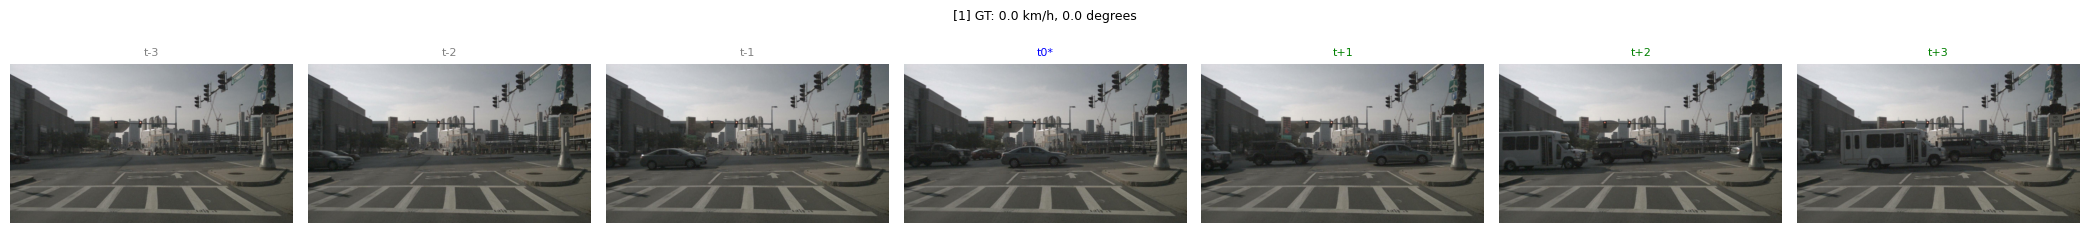


NON POST-HOC (4 images)...
Done in 92.1s
  Predicted: direction=going straight, speed=not moving
  GT:        direction=going straight, speed=not moving
  Match:     direction=OK, speed=OK, full=OK

POST-HOC (7 images)...
Done in 1309.2s
  Predicted: direction=going straight, speed=not moving
  GT:        direction=going straight, speed=not moving
  Match:     direction=OK, speed=OK, full=OK
Saved checkpoint.



Sample 8: c5f58c19249d...
GT speed:    8.421 m/s (30.3 km/h)
GT angle:    -2.58 degrees
GT accel:    0.187 m/s2
GT yaw rate: -3.17 deg/s


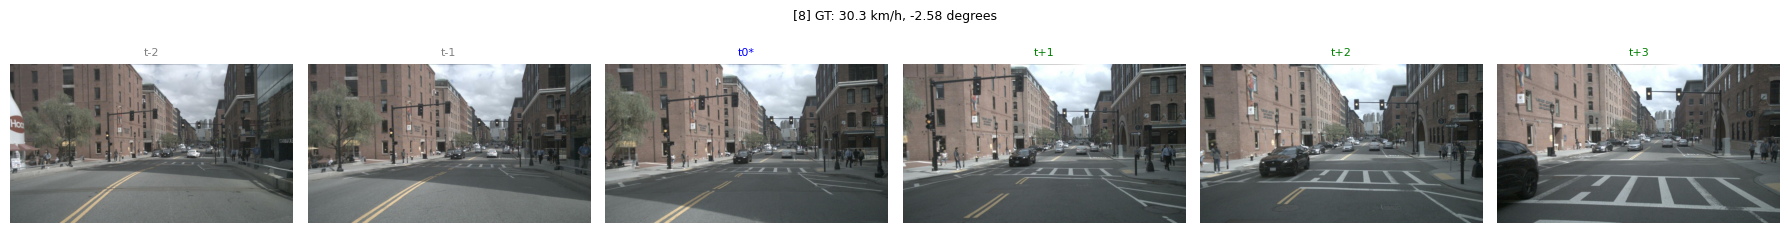


NON POST-HOC (3 images)...
Done in 142.1s
  Predicted: direction=going straight, speed=driving fast
  GT:        direction=going straight, speed=driving fast
  Match:     direction=OK, speed=OK, full=OK

POST-HOC (6 images)...
Done in 591.5s
  Predicted: direction=going straight, speed=driving fast
  GT:        direction=going straight, speed=driving fast
  Match:     direction=OK, speed=OK, full=OK
Saved checkpoint.



Smoke test complete. 2 samples saved.
File: results/smoke_test_v5_outputs.json


In [8]:
# CELL 6: Smoke test on a few scenario variants
# Index 0:  dc676572_v01 (scene 1, baseline)
# Index 1:  dc676572_v02 (scene 1, second K-map row)
# Index 30: first scene 2 variant
# ─────────────────────────────────────────────────────────────────────────────

smoke_results = []

for SAMPLE_IDX in [0, 1, 30]:
    s = data[SAMPLE_IDX]
    fd = s['frame_dir']
    gt = get_gt_continuous(s)
    n_past = s.get('n_past', 0)

    print(f"\n{'='*60}")
    print(f"Index {SAMPLE_IDX}: {s['sample_token']}")
    print(f"Scenario text: {s.get('scenario_text', '(none)')}")
    print(f"GT speed: {gt.get('avg_speed_mps')} m/s   GT accel: {gt.get('acceleration_mps2')} m/s2")

    # Show the 4 frames
    images = get_image_sequence(s)
    fig, axes = plt.subplots(1, len(images), figsize=(len(images)*3, 2.5))
    if len(images) == 1:
        axes = [axes]
    labels = (["t-3", "t-2", "t-1"][3-n_past:] if n_past < 3 else ["t-3", "t-2", "t-1"]) + ["t0"]
    for ax, path, label in zip(axes, images, labels):
        ax.imshow(Image.open(path))
        ax.set_title(label, fontsize=8, color='blue' if label == 't0' else 'gray')
        ax.axis('off')
    plt.suptitle(f"[{SAMPLE_IDX}] {s['sample_token']}", fontsize=9)
    plt.tight_layout()
    plt.show()

    print(f"\nRunning 3-step pipeline ({len(images)} images, sent at every step)...")
    t0 = time.time()
    result = run_condition_v3(s)
    elapsed = time.time() - t0
    print(f"Done in {elapsed:.1f}s")

    print(f"\nPlanning summary: {result['planning_summary'][:300]}")
    print(f"FINAL: direction={result['direction']}, speed={result['speed']}")
    if not result['speed'] or not result['direction']:
        print("WARNING: empty speed/direction -- check raw Step 3 output for this sample.")

    smoke_results.append({
        'sample_idx':    SAMPLE_IDX,
        'sample_token':  s['sample_token'],
        'scenario_text': s.get('scenario_text', ''),
        'gt_continuous': gt,
        'result':        result,
    })
    with open('results/smoke_test_scenarios_v3.json', 'w') as f:
        json.dump(smoke_results, f, indent=2)
    print("Saved checkpoint.")

print(f"\n{'='*60}")
print(f"Smoke test complete. {len(smoke_results)} samples saved.")
print("File: results/smoke_test_scenarios_v3.json")

In [8]:
# CELL 7: Full inference — Hamiltonian pass over all scenario variants (3-step)
# Checkpoints after every sample -- safe to interrupt and resume
# Output: results/scenario_hamiltonian_v3.json
# ─────────────────────────────────────────────────────────────────────────────

CHECKPOINT_FILE = 'results/scenario_hamiltonian_v3_checkpoint.json'
OUTPUT_FILE     = 'results/scenario_hamiltonian_v3.json'

N = len(data)
done_tokens = set()
results = []
if os.path.exists(CHECKPOINT_FILE):
    with open(CHECKPOINT_FILE) as f:
        results = json.load(f)
    done_tokens = {r['sample_token'] for r in results}
    print(f"Resuming from checkpoint: {len(done_tokens)}/{N} done")
else:
    print("Starting fresh run...")

total_start = time.time()

for idx, s in enumerate(data):
    if s['sample_token'] in done_tokens:
        print(f"[{idx+1}/{N}] Skipping {s['sample_token']} (already done)")
        continue

    gt = get_gt_continuous(s)
    scene_token = s.get('scene_token', s['sample_token'].rsplit('_v', 1)[0])

    print(f"\n[{idx+1}/{N}] {s['sample_token']} "
          f"(scene: {scene_token}) -- {s.get('scenario_text', '')[:60]}")

    t0 = time.time()
    result = run_condition_v3(s)
    elapsed = time.time() - t0
    print(f"  {elapsed:.1f}s -> direction={result['direction']}, speed={result['speed']}")
    if not result['speed'] or not result['direction']:
        print(f"  WARNING: empty speed/direction for {s['sample_token']}")

    results.append({
        'sample_token':  s['sample_token'],
        'scene_token':   scene_token,
        'scenario_text': s.get('scenario_text', ''),
        'gt_continuous': gt,
        'result':        result,
    })

    with open(CHECKPOINT_FILE, 'w') as f:
        json.dump(results, f, indent=2)

with open(OUTPUT_FILE, 'w') as f:
    json.dump(results, f, indent=2)

total_time = time.time() - total_start
n = len(results)
empty_count = sum(1 for r in results if not r['result']['speed'] or not r['result']['direction'])
dir_match = sum(r['result']['direction_correct'] for r in results) / n
spd_match = sum(r['result']['speed_correct']     for r in results) / n

print(f"\n{'='*55}")
print(f"DONE -- {n} samples in {total_time/60:.1f} minutes")
print(f"Empty speed/direction (parsing failures): {empty_count}/{n}")
print(f"\n[Diagnostic only -- compares against REAL recorded trajectory,")
print(f" not a scenario-aware ground truth]")
print(f"  Direction match rate: {dir_match:.3f}")
print(f"  Speed match rate:     {spd_match:.3f}")
print(f"\nSaved to: {OUTPUT_FILE}")

Resuming from checkpoint: 24/24 done
[1/24] Skipping 6dabc0fb... (already done)
[2/24] Skipping 37535cd3... (already done)
[3/24] Skipping 3ffc4360... (already done)
[4/24] Skipping b8766f42... (already done)
[5/24] Skipping e9a1c915... (already done)
[6/24] Skipping 27900b9c... (already done)
[7/24] Skipping 47188ae2... (already done)
[8/24] Skipping c5f58c19... (already done)
[9/24] Skipping fdc39b23... (already done)
[10/24] Skipping 6832e717... (already done)
[11/24] Skipping 61d9340c... (already done)
[12/24] Skipping 796b1988... (already done)
[13/24] Skipping 6d5d0e60... (already done)
[14/24] Skipping 78e778e7... (already done)
[15/24] Skipping 3a7aa284... (already done)
[16/24] Skipping 61d47d11... (already done)
[17/24] Skipping bc004007... (already done)
[18/24] Skipping a19a80c9... (already done)
[19/24] Skipping a1289b27... (already done)
[20/24] Skipping ac8b4d49... (already done)
[21/24] Skipping 858a1ece... (already done)
[22/24] Skipping 7bebe3c9... (already done)
[23/

In [1]:
# CELL 8: DriveLM planning pass (reuses frozen Steps 1-2 from Cell 7)
# ─────────────────────────────────────────────────────────────────────────────

with open('results/scenario_hamiltonian_v3.json') as f:
    hamiltonian_data = json.load(f)

N = len(hamiltonian_data)
drivelm_results = []
DRIVELM_CHECKPOINT = 'results/scenario_drivelm_v3_checkpoint.json'
DRIVELM_OUTPUT     = 'results/scenario_drivelm_v3.json'

if os.path.exists(DRIVELM_CHECKPOINT):
    with open(DRIVELM_CHECKPOINT) as f:
        drivelm_results = json.load(f)
    done_tokens = {r['sample_token'] for r in drivelm_results}
    print(f"Resuming: {len(done_tokens)}/{N} done")
else:
    done_tokens = set()
    print("Starting fresh run...")

for idx, r in enumerate(hamiltonian_data):
    if r['sample_token'] in done_tokens:
        continue
    s = data[idx]
    assert s['sample_token'] == r['sample_token'], "Sample order mismatch!"

    t0 = time.time()
    drivelm_result = run_planning_drivelm_v3(r['result'], s)
    elapsed = time.time() - t0

    entry = {
        'sample_token':  r['sample_token'],
        'scenario_text': r.get('scenario_text', ''),
        'hamiltonian':   r['result'],
        'drivelm':       drivelm_result,
    }
    drivelm_results.append(entry)

    print(f"[{idx+1}/{N}] {r['sample_token']} -- {elapsed:.1f}s -> "
          f"direction={drivelm_result['direction_drivelm']}, "
          f"speed={drivelm_result['speed_drivelm']}")
    if not drivelm_result['speed_drivelm'] or not drivelm_result['direction_drivelm']:
        print(f"  WARNING: empty speed/direction for {r['sample_token']} (drivelm)")

    with open(DRIVELM_CHECKPOINT, 'w') as f:
        json.dump(drivelm_results, f, indent=2)

with open(DRIVELM_OUTPUT, 'w') as f:
    json.dump(drivelm_results, f, indent=2)

print(f"\nDone. {len(drivelm_results)}/{N} samples saved to {DRIVELM_OUTPUT}")

NameError: name 'json' is not defined